In [13]:
using Pkg
Pkg.activate("/Users/alia/Desktop/envs/ants")
using Plots
using DifferentialEquations
using LaTeXStrings
using NLsolve
using IntervalArithmetic, IntervalArithmetic.Symbols, IntervalRootFinding
using LinearAlgebra
using Plots.PlotMeasures
xgfs_normal12 = [(235, 172, 35), (184, 0, 88), (0, 140, 249), (0, 110, 0), (0, 187, 173), (209, 99, 230), (178, 69, 2), (255, 146, 135), (89, 84, 214), (0, 198, 248), (135, 133, 0), (0, 167, 108), (189, 189, 189)]
pal = [RGB(r/255, g/255, b/255) for (r,g,b) in xgfs_normal12]

  Activating project at `~/Desktop/envs/ants`


In [2]:
function model_4d!(dx,x,p,t)
    (alphaC,alphaB,alphaT,beta,omegaC,omegaB,k,n,gamma)=p
    S,C,B,T = x
    H = 1 - S - B - C - T
    dx[1] = (-(alphaC+alphaB+alphaT)*S) + gamma*H
    dx[2] = alphaC*S - omegaC*C/(1+ (C/k)^n)
    dx[3] = alphaB*S - omegaB*B/(1+ (C/k)^n)
    dx[4] = alphaT*S - beta*T
    return nothing
end

model_4d! (generic function with 1 method)

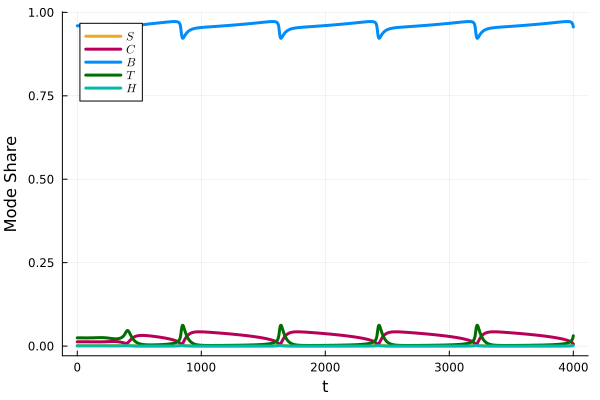

In [24]:
par = (alphaC = 0.4, alphaB = 0.3, alphaT = 0.8,beta = 0.07, omegaC = 1.2, omegaB = 0.012, k = 0.005, n = 3,gamma = 7.0)
u0 = [0.5,0.0,0.0,0.0]
u0 = [0.00216054 0.01280848 0.95987615 0.02469186]
tspan=(0.0,4000.0)

prob_4d = ODEProblem(model_4d!,u0,tspan,par)
sol4d = DifferentialEquations.solve(prob_4d,saveat = 1.0,Tsit5())
S4,C4,B4,T4 = sol4d[1,:],sol4d[2,:],sol4d[3,:],sol4d[4,:]
H4 = 1 .- S4 .- C4 .- B4 .-T4

p1 = plot(sol4d.t, vec(S4), label = L"S",  lw=3, color = pal[1],xlabel = "t",ylabel = "Mode Share")
plot!(p1, sol4d.t, vec(C4), label = L"C",   lw=3, color = pal[2])
plot!(p1, sol4d.t, vec(B4), label = L"B",   lw=3, color = pal[3])
plot!(p1, sol4d.t, vec(T4), label = L"T",   lw=3, color = pal[4])
plot!(p1, sol4d.t, vec(H4), label = L"H",   lw=3, color = pal[5])

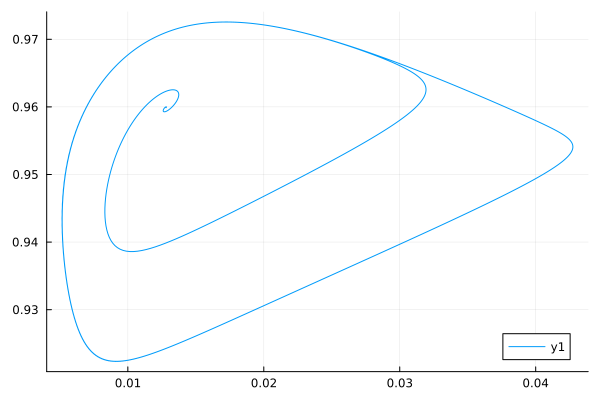

In [25]:
plot(vec(C4),vec(B4))